In [3]:
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [6]:
df = pd.read_csv("../employee_data.csv")
df.head()


,Employee_ID,Name,Age,Department,Salary,Joining_Date
0,101,Arun,25,IT,30000.0,2023-01-10
1,102,Priya,30,hr,45000.0,2022-05-15
2,103,Rahul,28,IT,NaN,2023-07-20
3,104,NaN,35,Finance,50000.0,2021-03-12
4,105,Divya,29,HR,40000.0,2022-08-01


In [5]:
df = pd.read_csv("employee_data.csv")
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'employee_data.csv'

In [7]:
df = pd.read_csv("../employee_data.csv")
df.head()

,Employee_ID,Name,Age,Department,Salary,Joining_Date
0,101,Arun,25,IT,30000.0,2023-01-10
1,102,Priya,30,hr,45000.0,2022-05-15
2,103,Rahul,28,IT,NaN,2023-07-20
3,104,NaN,35,Finance,50000.0,2021-03-12
4,105,Divya,29,HR,40000.0,2022-08-01


In [8]:
df.groupby("Department")

In [9]:
df.groupby("Department").mean()

TypeError: dtype 'str' does not support operation 'mean'

In [10]:
df.groupby("Department").mean(numeric_only=True)

,Employee_ID,Age,Salary
Department,,,
Finance,104.0,35.0,50000.0
HR,105.0,29.0,40000.0
IT,101.0,25.0,30000.0
IT,103.0,28.0,NaN
hr,102.0,30.0,45000.0


In [11]:
df["Department"]

0         IT
1         hr
2        IT 
3    Finance
4         HR
5         HR
Name: Department, dtype: str

In [12]:
df["Department"]= df["Department"].str.strip()

In [13]:
df["Department"] = df["Department"].str.upper()

In [14]:
print(df["Department"])

0         IT
1         HR
2         IT
3    FINANCE
4         HR
5         HR
Name: Department, dtype: str


In [15]:
df.groupby("Department").mean(numeric_only=True)

,Employee_ID,Age,Salary
Department,,,
FINANCE,104.0,35.000000,50000.000000
HR,104.0,29.333333,41666.666667
IT,102.0,26.500000,30000.000000


In [17]:
df.corr(numeric_only=True)

,Employee_ID,Age,Salary
Employee_ID,1.000000,0.462500,0.426805
Age,0.462500,1.000000,0.961067
Salary,0.426805,0.961067,1.000000


In [18]:
df.corr(numeric_only=True)


,Employee_ID,Age,Salary
Employee_ID,1.000000,0.462500,0.426805
Age,0.462500,1.000000,0.961067
Salary,0.426805,0.961067,1.000000


In [19]:
df.pivot_table(
    values="Salary",
    index="Department",
    aggfunc="mean"
)

,Salary
Department,
FINANCE,50000.000000
HR,41666.666667
IT,30000.000000


In [20]:
df.pivot_table(
    values="Salary",
    index=["Department", "Age"],
    aggfunc="mean"
)


Salary
Department Age         
FINANCE    35   50000.0
HR         29   40000.0
           30   45000.0
IT         25   30000.0

In [21]:
index=["Department", "Age"]

In [22]:
df.pivot_table(
    values="Salary",
    index="Age",
    columns="Department",
    aggfunc="mean"
)


Department,FINANCE,HR,IT
Age,,,
25,NaN,NaN,30000.0
29,NaN,40000.0,NaN
30,NaN,45000.0,NaN
35,50000.0,NaN,NaN


In [23]:
df.pivot_table(
    values="Employee_ID",
    index="Department",
    aggfunc="count"
)

,Employee_ID
Department,
FINANCE,1
HR,3
IT,2


In [25]:
df.pivot_table(
    values = "Salary",
    index="Department",
    aggfunc="max"
)

,Salary
Department,
FINANCE,50000.0
HR,45000.0
IT,30000.0


In [26]:
df.pivot_table(
    values="Salary",
    index="Department",
    aggfunc="min"
)

,Salary
Department,
FINANCE,50000.0
HR,40000.0
IT,30000.0


In [27]:
import matplotlib.pyplot as plt

In [34]:
from pathlib import Path
Path("reports/figures").mkdir(parents=True,exist_ok=True)

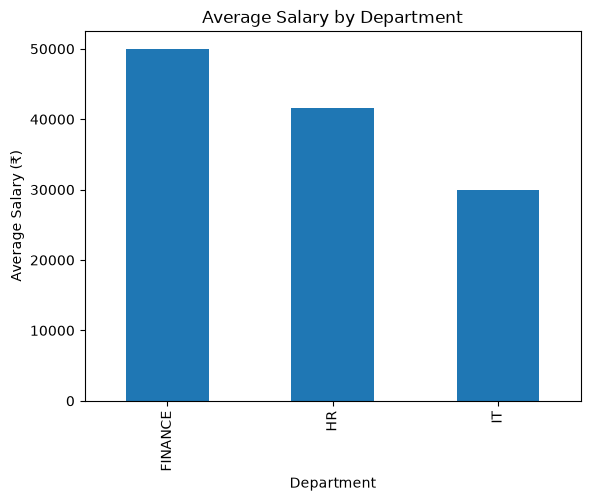

In [49]:
avg_salary = df.groupby("Department")["Salary"].mean()

avg_salary.plot(kind="bar")

plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary (₹)")
plt.savefig("reports/figures/bar_chart.png")
plt.show()

Salary distribution differs across department

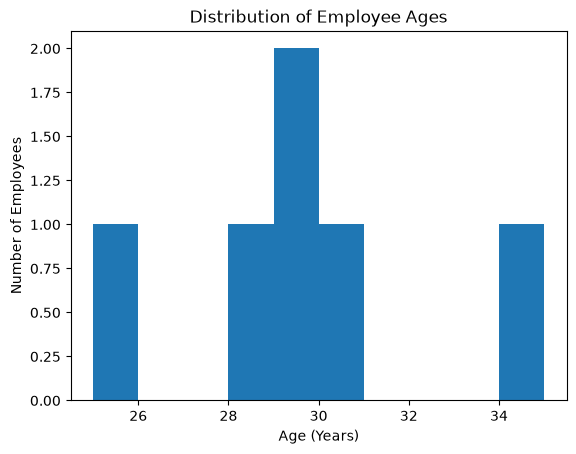

In [38]:
df["Age"].plot(kind="hist")

plt.title("Distribution of Employee Ages")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Employees")
plt.savefig("reports/figures/histogram.png")
plt.show()

Employee ages are distributed between 25 to 35 years

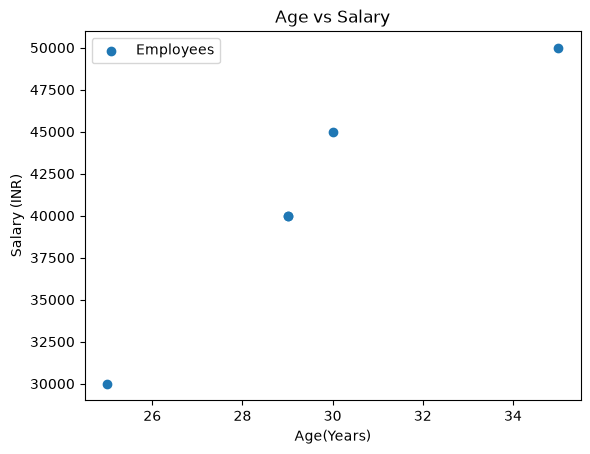

In [47]:
plt.scatter(df["Age"],df["Salary"],label="Employees")

plt.title("Age vs Salary")
plt.xlabel("Age(Years)")
plt.ylabel("Salary (INR)")
plt.legend()
plt.savefig("reports/figures/scatter_plot.png")
plt.show()

Age and Salary show a strong postive relationship in this dataset

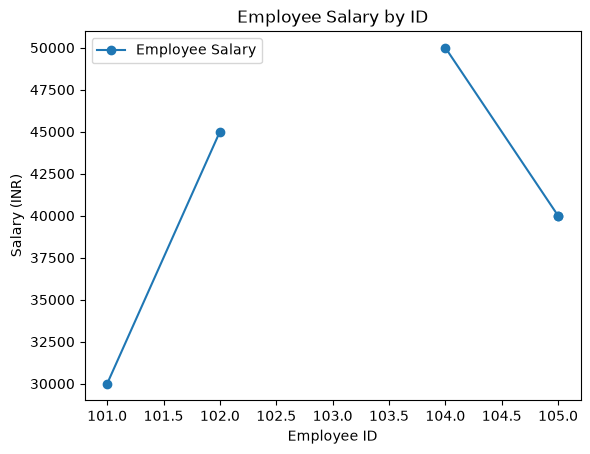

In [46]:
sorted_df = df.sort_values("Employee_ID")

plt.plot(
    sorted_df["Employee_ID"],
    sorted_df["Salary"],
    marker="o",
    label="Employee Salary"
)
plt.title("Employee Salary by ID")
plt.xlabel("Employee ID")
plt.ylabel("Salary (INR)")
plt.legend()

plt.savefig("reports/figures/line_chart.png")
plt.show()

Employee salaries vary across different employee IDs

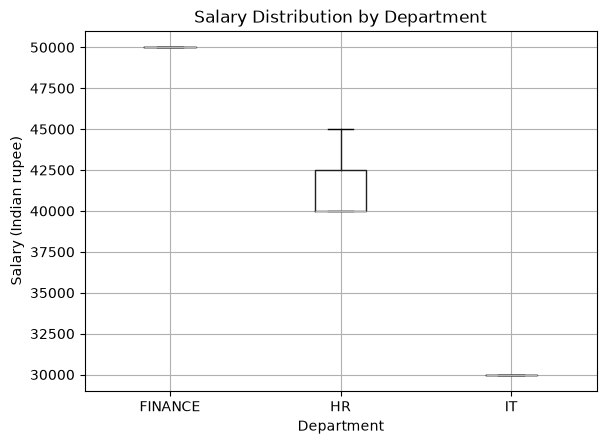

In [44]:
df.boxplot(column="Salary", by="Department")

plt.title("Salary Distribution by Department")
plt.suptitle("")
plt.xlabel("Department")
plt.ylabel("Salary (Indian rupee)")

plt.savefig("reports/figures/box_plot.png")
plt.show()


salary distribution differs across department